In [1]:
from pathlib import Path
import Auxiliary_function as F
import pandas as pd
import rasterio
from rasterio.windows import Window
import geopandas as gpd
import numpy as np
import os
from tqdm import tqdm
from pyproj import Transformer
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde
from Auxiliary_function import *

In [2]:
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

# y_true: 真实标签
# y_score: 模型输出概率
fpr, tpr, thresholds = roc_curve(y_true, y_score)

roc_auc = auc(fpr, tpr)

plt.plot(fpr, tpr, label=f"AUC = {roc_auc:.3f}")
plt.plot([0, 1], [0, 1], linestyle='--')  # 随机线
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.show()

NameError: name 'y_true' is not defined

In [ ]:
province = 'TW'
region_list  = ['Fuzhou', 'Putian', 'Quanzhou', 'Sanmen_gang', 'Sansha_bay', 'Zhangzhou', 'Sansha_bay', 'Zhangzhou', 'FujianSouth'] #FJ

region_list = ['Hangzhou_bay', 'Ningbo', 'Sanmen_bay', 'Taizhou', 'Wenzhou', 'Yueqing_bay'] #ZJ
region_list = ['Liaohe_estuary', 'Dalianshi', 'Dandong', 'Huludao', 'Liaodong_bay', 'Liaodong_bay2', 'Lichangshan'] #LN
region_list = ['Beibu_bay', 'Fangcheng_gang', 'Haikoushi', 'Lingaoshi','HN_west','Wenchangshi', 
                'Riyue_bay', 'Sanyashi', ] #'Leizhoushi',, 'Maomingshi' , 'Zhanjiangshi'
region_list = ['Leizhoushi','Maomingshi' , 'Zhanjiangshi']
region_list = [ 'Yangjiangshi', 'Jiangmenshi','Zhujiang_estuary', 'Xianggang', 'Shenquan_gang','Macau','Shantoushi','Shanweishi','Leizhoushi','Maomingshi' , 'Zhanjiangshi'] #GD
region_list = ['Taibeishi', 'Taidong', 'Tainan', 'Tainan2', 'Taizhong']
region_list = ['YRD','Dingzi_gang', 'Weihai', 'Dongyin_gang', 'Rushan_kou', 'Laoshan_bay','Wuleidao','Yantai', 
               'Wuleidao','Yantai', 'Huangjiatang_bay', 'Laizhou_bay', 'Laizhou_bay2','Laizhou_bay3', 'Bohai_bay1', 'Huangjiatang_bay']  #'Jiaozhou_bay
region_list = [ 'Jiaozhou_bay']
region_list = ['Dongsha', 'Nantong', 'Sheyang_estuary', 'Guanghe_estuary', 'Haizhou_bay', 'Shanghai'] #JS
region_list = ['Hangzhou_bay', 'Ningbo', 'Sanmen_bay', 'Taizhou', 'Wenzhou', 'Yueqing_bay'] #ZJ
region_list  = ['Fuzhou', 'Putian', 'Quanzhou', 'Sanmen_gang', 'Sansha_bay', 'Zhangzhou', 'Sansha_bay', 'Zhangzhou', 'FujianSouth'] #FJ
region_list = ['Beibu_bay', 'Fangcheng_gang']
# region_list = ['Bohai_bay1', 'Bohai_bay2', 'Bohai_bay3']
# region_list = ['Liaohe_estuary', 'Dalianshi', 'Dandong', 'Huludao', 'Liaodong_bay', 'Liaodong_bay2', 'Lichangshan'] #LN
region_list = [ 'Yangjiangshi', 'Jiangmenshi','Zhujiang_estuary', 'Xianggang', 'Shenquan_gang','Macau','Maomingshi' , 'Zhanjiangshi'
               'Shantoushi','Shanweishi','Leizhoushi','Maomingshi' , 'Zhanjiangshi', 'Shenquan_gang','Macau','Shantoushi','Shanweishi',] #GD 
region_list = [ 'Haikoushi', 'Lingaoshi','HN_west','Wenchangshi', 'Riyue_bay', 'Sanyashi', ] 
region_list =  ['Bohai_bay2', 'Bohai_bay3', 'Qinghuangdao'] 
region_list = ['Taibeishi', 'Taidong', 'Tainan', 'Tainan2', 'Taizhong']
year_list  = [2025]

for region in region_list:
    for year in year_list:
        
        # FB_RASTER_PATH = f"G:\paper5\Paper5_data\Input_data\{province}\{region}_{year}_new9.tif"
        FB_RASTER_PATH = f"G:\paper5\Paper5_data\combine_FB\{province}\{region}_{year}_combine.tif"
        # FB_RASTER_PATH = f"H:\paper5\Paper5_data\Input_data\GD\{region}_{year}_new9.tif"
        ICESAT_CSV = f'G:\paper5\Paper5_data\ICESat_2\{province}_ICESat_2\{region}\A_{region}_30m_{year}_30.csv'
        # ICESAT_CSV = F'H:\paper5\Paper5_data\ICESat_2\JS_ICESat_2\JS_SH_Shanghai\A_{region}_30m_{year}_30.csv'
        OUTPUT_FILTERED = f'G:\paper5\Paper5_data\ICESat_2\{province}_ICESat_2\{region}\A_{region}_30m_{year}.shp'
        OUTPUT_RAW = f'G:\paper5\Paper5_data\ICESat_2\{province}_ICESat_2\{region}\A_{region}_30m_{year}_raw.shp'

        final_data = load_refer_icesat_point_optimized_shp(
            FB_RASTER_PATH, 
            ICESAT_CSV, 
            OUTPUT_FILTERED, 
            OUTPUT_RAW,
            oh_threshold=5, # 将 OH 阈值设为 3.0
            b8_min=0    # 将 b8 波段最小值设为 10.0
        )


In [ ]:
province = 'LN'

year_list  = [2019, 2020, 2021, 2022, 2023, 2024]
year_list = [2025]

#---------------------------------------LN-----------------------------------------
region_list = [ 'Lichangshan', 'Liaohe_estuary', 'Dalianshi',  'Dandong', 'Huludao', 'Liaodong_bay','Liaodong_bay2',] #LN 
#---------------------------------------HB-----------------------------------------
region_list = ['Bohai_bay2', 'Bohai_bay3', 'Qinghuangdao'] #HB
#---------------------------------------SD-----------------------------------------
region_list = ['YRD','Dingzi_gang', 'Jiaozhou_bay', 'Dongyin_gang', 'Rushan_kou', 'Laoshan_bay','Wuleidao','Yantai', 
               'Wuleidao','Yantai', 'Huangjiatang_bay', 'Laizhou_bay', 'Laizhou_bay2','Laizhou_bay3', 'Bohai_bay1', 'Huangjiatang_bay'] # 'Weihai','Yantai' ,,'Laizhou_bay3'
#---------------------------------------ZJ-----------------------------------------
region_list = ['Hangzhou_bay', 'Ningbo', 'Sanmen_bay', 'Taizhou', 'Wenzhou', 'Yueqing_bay'] # ZJ
#---------------------------------------FJ-----------------------------------------
region_list  = ['Fuzhou', 'Putian', 'Quanzhou', 'Sanmen_gang', 'Sansha_bay', 'Zhangzhou', 'Sansha_bay', 'Zhangzhou', 'FujianSouth'] #FJ
#---------------------------------------GD-----------------------------------------
region_list = [ 'Yangjiangshi', 'Jiangmenshi','Zhujiang_estuary', 'Xianggang', 'Shenquan_gang','Macau','Shantoushi','Shanweishi','Leizhoushi',
               'Maomingshi' , 'Zhanjiangshi']
#---------------------------------------JS-----------------------------------------
region_list = ['Nantong', 'Dongsha', 'Sheyang_estuary', 'Guanghe_estuary', 'Haizhou_bay', 'Shanghai']
#---------------------------------------TW-----------------------------------------
region_list = ['Taibeishi', 'Taidong', 'Tainan', 'Tainan2', 'Taizhong'] 
#---------------------------------------GX-----------------------------------------
region_list = ['Beibu_bay', 'Fangcheng_gang']
#---------------------------------------HN-----------------------------------------
region_list = [ 'Haikoushi', 'Lingaoshi','HN_west','Wenchangshi'] #, 'Riyue_bay', 'Sanyashi'

region_list = [ 'Lichangshan', 'Liaohe_estuary', 'Dalianshi',  'Dandong', 'Huludao', 'Liaodong_bay','Liaodong_bay2',] #LN 

for region in region_list:
    
    for year in year_list:
        
        FB_RASTER_PATH = f"G:\paper5\Paper5_data\combine_FB\{province}\{region}_{year}_combine.tif"
        # FB_RASTER_PATH = f"H:\paper5\Paper5_data\Input_data\GD\{region}_{year}_new9.tif"
        SHP_PATH = f'G:\paper5\Paper5_data\ICESat_2\{province}_ICESat_2\{region}\A_{region}_30m_{year}_refined.shp'
        # ICESAT_CSV = F'H:\paper5\Paper5_data\ICESat_2\JS_ICESat_2\JS_SH_Shanghai\A_{region}_30m_{year}_30.csv'
        OUTPUT_FILTERED = f'G:\paper5\Paper5_data\ICESat_2\{province}_ICESat_2\{region}\A_{region}_30m_{year}_refined2.shp'

        final_data = load_refer_icesat_point_optimized_shp2(
            FB_RASTER_PATH, 
            SHP_PATH, 
            OUTPUT_FILTERED, 
            oh_threshold=5, # 将 OH 阈值设为 3.0
            b8_min=0    # 将 b8 波段最小值设为 10.0
        )

In [200]:

def ICESAT_Refined(ICESat_path, band, mask_apply, oh_mask, Freq_mask, output_to_new_shp ,oh_mask1, Freq_mask1, rename ,display=True):

    a = gpd.read_file(ICESat_path)

    if mask_apply:
        mask = (a['OH'] > oh_mask[0]) & (a[band] < Freq_mask[0]) 
        for j in range(1 ,len(oh_mask)):
            mask = mask | ((a['OH'] > oh_mask[j]) & (a[band] < Freq_mask[j]))
        
        mask = mask | (a['OH'] < oh_mask1[0]) & (a[band] > Freq_mask1[0])
        for j in range(1 ,len(oh_mask1)):
            mask = mask | (a['OH'] < oh_mask1[j]) & (a[band] > Freq_mask1[j])
        # mask = mask | (a['OH'] < -2)
        a = a[~mask]

    y_true = a['OH'].values
    y_pred = a[band].values

    xy = np.vstack([y_true, y_pred])
    z = gaussian_kde(xy)(xy)
    idx = z.argsort()
    x, y, z = y_true[idx], y_pred[idx], z[idx]

    if mask_apply & output_to_new_shp:
        p = Path(ICESat_path)
        new_p = p.with_name(p.stem + rename + p.suffix)
        print(f'New files output to {new_p}')
        a.to_file(new_p)

    if display:

        fig, ax = plt.subplots(figsize=(6, 6))

        sc = ax.scatter(
            x, y,
            c=z,
            s=8,
            cmap='viridis',
            edgecolor='none'
        )

        plt.title(f'{region}_{year}', fontsize=16)

        if band == 'b1_FB6':
            limsx = [-2, 4]
            limsy = [0, 1]
            ax.plot(limsx, limsy, 'r--', linewidth=1)
            ax.set_xlim(limsx)
            ax.set_xticks(np.arange(limsx[0], limsx[1] + 0.001, 0.5))
            ax.set_ylim(limsy)
            ax.set_yticks(np.arange(limsy[0], limsy[1] + 0.001, 0.1))
        textstr = f'num = {len(a)}'
        ax.text(
            0.05, 0.95, textstr,
            transform=ax.transAxes,   # 使用轴坐标系
            fontsize=16,
            verticalalignment='top',
            horizontalalignment='left',
            bbox=dict(facecolor='white', alpha=0.7, edgecolor='none')
        )

        ax.grid(
            True,
            which='both',
            linestyle='--',
            linewidth=0.6,
            color='gray',
            alpha=0.6
        )
        plt.tight_layout()
        plt.show()

In [ ]:

province = 'GX'

# region_list  = ['Fuzhou', 'Putian', 'Quanzhou', 'Sanmen_gang', 'Sansha_bay',   'Zhangzhou', 'FujianSouth']
region_list = ['Bohai_bay2', 'Bohai_bay3', 'Qinghuangdao']
region_list = ['Taibeishi', 'Taidong', 'Tainan', 'Tainan2', 'Taizhong']

region = 'Beibu_bay'
year = 2024
path = f'G:\paper5\Paper5_data\ICESat_2\{province}_ICESat_2\{region}\A_{region}_30m_{year}.shp'

True
ICESAT_Refined(ICESat_path = path,
               band = 'b1_FB6',
               mask_apply = True,  #False True
               oh_mask   = [0.50, 1.00, 1.5, 2.0, 1.7, 1.75],
               Freq_mask = [0.15, 0.36, 0.6, 1.0, 0.65, 0.8],
               output_to_new_shp=True,
               oh_mask1 =   [1.0],
               Freq_mask1 = [0.8],
               rename= '_refined2'
               )

In [ ]:
import geopandas as gpd
import numpy as np

# 读取数据

year_list = [2019, 2020, 2021, 2022, 2023, 2024]
province = 'GX'
region_list = [ 'Beibu_bay']

for region in region_list:

        for year in year_list:
    
                ICESat_path = f'G:/paper5/Paper5_data/ICESat_2/{province}_ICESat_2/{region}/A_{region}_30m_{year}_refined2.shp'
                Test_output_path = f'G:/paper5/Paper5_data/ICESat_2/{province}_ICESat_2/{region}/A_{region}_30m_{year}_refined2_test.shp'
                Train_output_path = f'G:/paper5/Paper5_data/ICESat_2/{province}_ICESat_2/{region}/A_{region}_30m_{year}_refined2_train.shp'

                if not os.path.exists(ICESat_path):
                        print(f"File not found, skip: {ICESat_path}")
                        continue
                
                gdf = gpd.read_file(ICESat_path)
                print(f"Processing: {region} {year}")

                # 提取 strip group（前5个字符）
                gdf["strip_group"] = gdf["Strip_No"].str[:5]

                # 获取唯一 strip
                strips = gdf["strip_group"].unique()

                # 打乱顺序
                np.random.seed(42)
                np.random.shuffle(strips)

                # 8:2 划分
                n_test = max(1, round(len(strips) * 0.2))

                test_strips = strips[:n_test]
                train_strips = strips[n_test:]

                print("Test strips:", test_strips)
                print("Train strips:", train_strips)

                # 按 strip_group 划分
                test_gdf = gdf[gdf["strip_group"].isin(test_strips)]
                train_gdf = gdf[gdf["strip_group"].isin(train_strips)]

                # 统计
                print("Total points:", len(gdf))
                print("Test points:", len(test_gdf))
                print("Train points:", len(train_gdf))

                print("Test ratio:", len(test_gdf) / len(gdf))
                print("Train ratio:", len(train_gdf) / len(gdf))

                # 删除临时字段（避免写入 shp）
                test_gdf = test_gdf.drop(columns=["strip_group"])
                train_gdf = train_gdf.drop(columns=["strip_group"])

                # 保存
                test_gdf.to_file(Test_output_path)
                train_gdf.to_file(Train_output_path)

In [155]:
import os

shp_dir = r"H:\paper5\Paper5_data\ICESat_2\JS_ICESat_2\JS_SH_Dongsha"

shp_files = [
    f for f in os.listdir(shp_dir)
    if f.lower().endswith("_refined.shp")
    
]

print(shp_files)


['A_Dongsha_30m_2022_refined.shp', 'A_Dongsha_30m_2023_refined.shp', 'A_Dongsha_30m_2024_refined.shp']


In [3]:
import pandas as pd
import warnings
import rasterio
from rasterio.windows import Window
import geopandas as gpd
import numpy as np
import os
from tqdm import tqdm
from pyproj import Transformer

def create_training_patches(
    shp_path: str, 
    tif_path: str, 
    patch_size: int ,
    output_dir: str = 'G:\paper5\Paper5_data\Training\Anew'
):
    """
    
    根据 ICESat-2 点的地理坐标，从多波段 GeoTIFF 中提取指定大小的图像块。

    Args:
        csv_path (str): ICESat-2 点数据 (lat, lon, elevation) 的 CSV 文件路径。
        tif_path (str): 多波段光学影像 GeoTIFF 文件路径。
        patch_size (int): 图像块的边长 (例如 15 表示 15x15)。
        output_dir (str): 存储提取的图像块和标签的输出目录。

    """
    
    # --- 1. 数据准备和初始化 ---
    
    # 创建输出目录
    if not os.path.exists(output_dir):
        os.makedirs(output_dir)

    if not os.path.exists(shp_path):
        warnings.warn(f"Warning: shapefile not found, skip -> {shp_path}")
        return None, None
    
    df_icesat = gpd.read_file(shp_path)
    
    # 确定图像块的半边长
    half_patch = patch_size // 2
    
    # 用于存储所有样本的列表
    all_patches = []
    all_labels = []
    
    # --- 2. 打开 GeoTIFF 文件 ---
    print(f"正在打开 GeoTIFF 文件: {tif_path}")
    
    try:
        with rasterio.open(tif_path) as src:
            # 记录 CRS 信息（通常是投影坐标系）
            raster_crs = src.crs
            print(f"GeoTIFF CRS: {raster_crs}")
            
            transformer = Transformer.from_crs('EPSG:4326', raster_crs, always_xy=True)
            # --- 3. 循环处理每个 ICESat-2 点 ---
            print(f"总共 {len(df_icesat)} 个 ICESat-2 点需要处理...")
            
            for index, row in tqdm(df_icesat.iterrows(), total=len(df_icesat), desc="提取图像块"):
                lon, lat, elevation = row['mean_lon'], row['mean_lat'], row['OH']
                x, y = transformer.transform(lon, lat)
                # --- 3.1 坐标转换（地理坐标到像素坐标）---
                # 使用 rasterio.index() 方法将地理坐标 (lon, lat) 转换为 (row, col)
                # 注意: rasterio 默认使用 WGS84/EPSG:4326 作为输入地理坐标
                
                try:
                    row_idx, col_idx = src.index(x, y)
                except Exception as e:
                    # 如果坐标点在 GeoTIFF 范围之外，跳过
                    # print(f"警告: 点 ({lon}, {lat}) 位于栅格范围外，已跳过。")
                    continue
                
                # --- 3.2 定义提取窗口（Window）---
                # 确定窗口的左上角 (col_off, row_off)
                col_off = col_idx - half_patch
                row_off = row_idx - half_patch
                
                # 创建一个 rasterio.windows.Window 对象
                window = Window(col_off, row_off, patch_size, patch_size)
                
                # --- 3.3 边界检查和切片提取 ---
                
                # 检查窗口是否完全在栅格范围内
                if (col_off >= 0 and row_off >= 0 and 
                    (col_off + patch_size) <= src.width and 
                    (row_off + patch_size) <= src.height):
                    
                    # 读取图像块
                    # read(..., window=...) 是从 GeoTIFF 文件中高效读取子集的关键
                    patch = src.read(window=window)
                    
                    # 调整维度顺序 (C, H, W) -> (H, W, C) 以便后续DL处理或可视化
                    # 如果您的 DL 框架 (如 PyTorch) 偏好 (C, H, W)，则无需此步
                    patch = np.transpose(patch, (1, 2, 0)) 
                    
                    # --- 3.4 存储样本 ---
                    all_patches.append(patch)
                    all_labels.append(elevation)

                else:
                    # 图像块位于边界，不完整，跳过（或用零填充，但跳过更安全）
                    # print(f"警告: 图像块 {index} 位于边界，跳过。")
                    pass

    except rasterio.RasterioIOError as e:
        print(f"错误: 无法读取 GeoTIFF 文件 {tif_path}。请检查路径和文件完整性。")
        print(e)
        return 
    
    # --- 4. 结果整理与保存 ---
    
    # 将列表转换为 NumPy 数组
    X_train = np.array(all_patches)
    Y_train = np.array(all_labels)
    
    # 打印最终统计信息
    print("\n--- 提取完成 ---")
    print(f"成功提取的样本数量: {len(Y_train)}")
    print(f"输入特征 (X_train) 形状: {X_train.shape} (N, H, W, C)")
    print(f"标签 (Y_train) 形状: {Y_train.shape} (N, )")
    
    return X_train, Y_train

In [4]:
All_region_list = {
    
    'province1':{'name':'LN', 'region_list':[ 'Lichangshan', 'Liaohe_estuary', 'Dalianshi',  'Dandong', 'Huludao', 'Liaodong_bay2',]}, #'Liaodong_bay',
    'province2':{'name':'HB', 'region_list':['Bohai_bay2', 'Bohai_bay3', 'Qinghuangdao']},
    'province3':{'name':'SD', 'region_list':['Dingzi_gang', 'Jiaozhou_bay',  'Rushan_kou', 'Laoshan_bay','Wuleidao','Yantai', 
               'Wuleidao','Yantai', 'Huangjiatang_bay', 'Laizhou_bay3', 'Bohai_bay1', 'Huangjiatang_bay', 'YRD','Dongyin_gang', 'Laizhou_bay']},
    'province4':{'name':'JS', 'region_list':['Nantong', 'Dongsha', 'Sheyang_estuary', 'Guanghe_estuary', 'Haizhou_bay', 'Shanghai']},
    'province5':{'name':'ZJ', 'region_list':[ 'Ningbo', 'Sanmen_bay', 'Taizhou', 'Wenzhou', 'Yueqing_bay', 'Hangzhou_bay']},
    'province6':{'name':'FJ', 'region_list':['Fuzhou', 'Putian', 'Quanzhou', 'Sanmen_gang', 'Sansha_bay', 'Zhangzhou', 'Sansha_bay', 'Zhangzhou', 'FujianSouth']},
    'province7':{'name':'GD', 'region_list':[ 'Yangjiangshi', 'Jiangmenshi','Zhujiang_estuary', 'Xianggang', 'Shenquan_gang','Macau','Shantoushi','Shanweishi','Leizhoushi',
               'Maomingshi' , 'Zhanjiangshi']},
    'province8':{'name':'TW', 'region_list': ['Taibeishi', 'Taidong', 'Tainan', 'Tainan2', 'Taizhong']},
    'province9':{'name':'GX', 'region_list':  ['Beibu_bay', 'Fangcheng_gang']},
    'province10':{'name':'HN', 'region_list': [ 'Haikoushi', 'Lingaoshi','HN_west','Wenchangshi']}
    
}#
# JS \
# ZJ 

In [ ]:
PATCH_SIZE = 13

X_list, Y_list = [], []

for i in range(1, 11):
    
    province = All_region_list[f'province{i}']['name']
    
    year_list = [2019, 2020, 2021, 2022, 2023]
    year_list = [2025]
    # year_list = [2025]

    region_list = All_region_list[f'province{i}']['region_list']

    for year in year_list:
        
        for region in region_list:
            
            shp_file = Path(f"G:/paper5/Paper5_data/ICESat_2/{province}_ICESat_2/{region}/A_{region}_30m_{year}_refined2.shp")
            tif_file = Path(f"G:/paper5/Paper5_data/combine_FB/{province}/{region}_{year}_combine.tif")
            
            X, Y = create_training_patches(
                str(shp_file),
                str(tif_file),
                patch_size=PATCH_SIZE
            )

            if X is None:
                continue
            
            if len(X.shape) != 4:
                print(f"Skip bad X shape: {X.shape}")
                continue

            if X.shape[0] == 0:
                print("Skip empty sample")
                continue
            
            X_list.append(X)
            Y_list.append(Y)
            
X_train_all = np.concatenate(X_list, axis=0)
Y_train_all = np.concatenate(Y_list, axis=0)

print(f"X_train shape: {X_train_all.shape}")
print(f"Y_train shape: {Y_train_all.shape}")

In [ ]:
print(f"X_train shape: {X_train_all.shape}")
print(f"Y_train shape: {Y_train_all.shape}")
output_dir = 'G:\paper5\Paper5_data\Training\China_training_data'

np.save(os.path.join(output_dir, 'Y_train_24_25_China_new3.npy'), Y_train_all)
np.save(os.path.join(output_dir, 'X_train_24_25_China_new3.npy'), X_train_all)

X_train shape: (392831, 13, 13, 12)
Y_train shape: (392831,)


In [99]:
import numpy as np

# X_dir = r'G:\paper5\Paper5_data\Training\China_training_data\X_train_19_03_China_new3.npy'
# Y_dir = r'G:\paper5\Paper5_data\Training\China_training_data\Y_train_19_03_China_new3.npy'

# X_train_all = np.load(X_dir)
# Y_train_all = np.load(Y_dir)

# # 提取中心像元
y_pred = X_train_all[:, 6, 6, 0]
y_ = X_train_all[:, 6, 6, 9]
y_true = Y_train_all


# # 构建mask
# mask2 = (y_true > -2.2 | y_pred < 0.2)

mask = (
    (y_pred >= 0.05) &
    (y_pred <= 1.6) &
    (y_true <= 4.2) &
    (y_true > -2.7) &
    ~((y_true > 3) & (y_pred < 0.6)) &
    ~((y_true < -2.2) & (y_pred >0.2)) &
    ~((y_true < -1.8) & (y_pred >0.4)) &~((y_true < -0.75) & (y_pred >0.7))&~((y_true < -1.5) & (y_pred >0.5)) &~((y_true > 2) & (y_pred <0.2))
)
# 数据清洗
X_clean = X_train_all[mask]
Y_clean = Y_train_all[mask]

print("原始样本数:", len(X_train_all))
print("清洗后样本数:", len(X_clean))
print("清洗后样本数:", len(Y_clean))


原始样本数: 72296
清洗后样本数: 72081
清洗后样本数: 72081


In [ ]:
output_dir = 'G:\paper5\Paper5_data\Training\China_training_data'

np.save(os.path.join(output_dir, 'Y_test_25_China_new3.npy'), Y_clean)
np.save(os.path.join(output_dir, 'X_test_25_China_new3.npy'), X_clean)

In [101]:
X_dir = r'G:\paper5\Paper5_data\Training\China_training_data\X_train_19_23_China_new3.npy'
Y_dir = r'G:\paper5\Paper5_data\Training\China_training_data\Y_train_19_23_China_new3.npy'

X_train_all = np.load(X_dir)
Y_train_all = np.load(Y_dir)


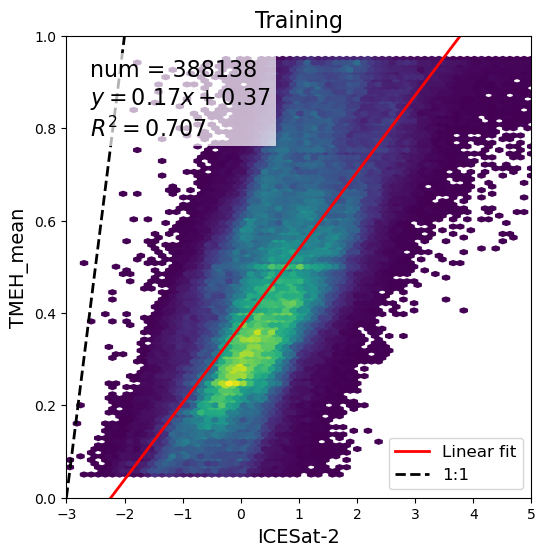

In [103]:
from scipy.stats import pearsonr
fig, ax = plt.subplots(figsize=(6, 6))

# y_pred = X_clean[:, 6, 6, 0]
# y_true = Y_clean
    
y_pred = X_train_all[:, 6, 6, 0 ]
y_true = Y_train_all
# y_true = a['OH'].values
# y_pred = a['b1_FB6'].values

hb = ax.hexbin(
    y_true, y_pred,
    gridsize=100,
    cmap='viridis',
    mincnt=1
)
# ===============================
# 线性拟合 + R²
# ===============================
mask = np.isfinite(y_true) & np.isfinite(y_pred)

# 拟合
k, b = np.polyfit(y_true[mask], y_pred[mask], 1)

x_fit = np.array([
    y_true[mask].min(),
    y_true[mask].max()
])
y_fit = k * x_fit + b

ax.plot(
    x_fit, y_fit,
    'r-', linewidth=2,
    label='Linear fit'
)
ax.set_xlim(-3, 5)   # x 轴范围
ax.set_ylim(0, 1)  
# ---------------- 坐标轴名称 ----------------
ax.set_xlabel('ICESat-2', fontsize=14)
ax.set_ylabel('TMEH_mean', fontsize=14)

# R²
y_hat = k * y_true[mask] + b
ss_res = np.sum((y_pred[mask] - y_hat) ** 2)
ss_tot = np.sum((y_pred[mask] - np.mean(y_pred[mask])) ** 2)
#r2 = 1 - ss_res / ss_tot
r2, p_value = pearsonr(y_true[mask], y_pred[mask])

lims = [
    min(y_true[mask].min(), y_pred[mask].min()),
    max(y_true[mask].max(), y_pred[mask].max())
]
# ax.plot([-3, 5], [-3, 5], 'k--', linewidth=2, label='1:1')
ax.plot([-3, 5], [0,8], 'k--', linewidth=2, label='1:1')

# ===============================
# 左上角文本框（num + 公式 + R²）
# ===============================
textstr = (
    f'num = {mask.sum()}\n'
    f'$y = {k:.2f}x {b:+.2f}$\n'
    f'$R^2 = {r2:.3f}$'
)
# plt.colorbar(hb, ax=ax, label='count')
ax.text(
    0.05, 0.95, textstr,
    transform=ax.transAxes,
    fontsize=16,
    verticalalignment='top',
    horizontalalignment='left',
    bbox=dict(facecolor='white', alpha=0.7, edgecolor='none')
)
plt.title(f'Training', fontsize=16)
ax.legend(fontsize=12)

In [163]:
from sklearn.model_selection import train_test_split

X_train, X_test, Y_train, Y_test = train_test_split(
    X_train_all,
    Y_train_all,
    test_size=0.2,      # 30% 作为测试集
    random_state=42,    # 固定随机种子，结果可复现
    shuffle=True
)
output_dir = 'H:/paper5_code/training_data_patches'
print("Train X:", X_train.shape)
print("Train y:", Y_train.shape)
print("Test X :", X_test.shape)
print("Test y :", Y_test.shape)

np.save(os.path.join(output_dir, 'X_train_JS.npy'), X_train)
np.save(os.path.join(output_dir, 'Y_train_JS.npy'), Y_train)
np.save(os.path.join(output_dir, 'X_test_JS.npy'), X_test)
np.save(os.path.join(output_dir, 'Y_test_JS.npy'), Y_test)

Train X: (84809, 13, 13, 12)
Train y: (84809,)
Test X : (21203, 13, 13, 12)
Test y : (21203,)


In [ ]:
def draw_validation_plot2(
    refer_name,
    validation_point_path,
    retrieved_DTM_name,
    std_std,
    output_path,
    name,
    xy_lim_range,
    vmax,
    kde_sample_size=5000   # ⭐关键参数
):

    # ======================
    # 1. 读取 + 筛选
    # ======================
    gdf = gpd.read_file(validation_point_path)

    # ======================
    # 2. 严格筛选（安全写法）
    # ======================
    z = gdf.dropna(subset=[refer_name, retrieved_DTM_name, 'std'])

    z = z[
        (z[refer_name] != 0) &
        (z[retrieved_DTM_name] != 0) &
        (z[refer_name] != -999) &
        (z[retrieved_DTM_name] != -999) &
        (z[refer_name] != 6) &
        (z[retrieved_DTM_name] != 6) &
        (z[refer_name] < 6) &
        (z[retrieved_DTM_name] > -5) &
        (z['std'] < std_std)
    ]


    x = z[refer_name].values
    y = z[retrieved_DTM_name].values

    # ======================
    # 2. 指标
    # ======================
    diff = y - x
    R2 = r2_score(x, y)
    MAE = np.mean(np.abs(diff))
    RMSE = np.sqrt(np.mean(diff**2))
    num = len(x)

    print(f"R²={R2:.3f}, MAE={MAE:.3f}, RMSE={RMSE:.3f}, N={num}")

    # ======================
    # 3. KDE（只用子样本）
    # ======================
    N = len(x)

    if N > kde_sample_size:
        idx_sample = np.random.choice(N, kde_sample_size, replace=False)
    else:
        idx_sample = np.arange(N)

    xy_sample = np.vstack([x[idx_sample], y[idx_sample]])
    kde = gaussian_kde(xy_sample)

    # ⭐ 对所有点计算密度（关键技巧）
    xy_all = np.vstack([x, y])
    z_density = kde(xy_all)

    # ======================
    # 4. 排序（保证视觉效果）
    # ======================
    idx = z_density.argsort()
    x_sorted = x[idx]
    y_sorted = y[idx]
    z_sorted = z_density[idx]

    # ======================
    # 5. 绘图
    # ======================
    fig, ax = plt.subplots()

    sc = ax.scatter(
        x_sorted,
        y_sorted,
        c=z_sorted,
        s=5,
        cmap='Spectral_r',
        vmin=0,
        vmax=vmax
    )

    cbar = plt.colorbar(sc)
    cbar.ax.tick_params(labelsize=14)

    xmin, xmax = xy_lim_range[0], xy_lim_range[1]

    # 1:1线
    ax.plot([xmin, xmax], [xmin, xmax], '--', color='gray', linewidth=0.8)

    # 文本
    textstr = f"R² = {R2:.2f}\nMAE = {MAE:.2f}\nRMSE = {RMSE:.2f}\nN = {num}"
    ax.text(0.52, 0.05, textstr, transform=ax.transAxes, fontsize=20)
    ax.text(0.05, 0.95, name, transform=ax.transAxes, fontsize=20)

    # 坐标轴
    ax.set_xlabel('Airborne LiDAR DEM', fontsize=18)
    ax.set_ylabel('Retrieved DEM', fontsize=18)

    ax.set_xlim(xmin, xmax)
    ax.set_ylim(xmin, xmax)

    ticks = np.arange(xmin, xmax + xy_lim_range[2], xy_lim_range[2])
    ax.set_xticks(ticks)
    ax.set_yticks(ticks)
    ax.tick_params(labelsize=16)

    plt.show()
    # plt.savefig(output_path, dpi=300, bbox_inches='tight')
    # plt.close()

    print("绘图完成！")
    
    return z